In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd                                        
import tensorflow_datasets as tfds

C:\Users\Sanika\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [2]:
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import models,layers
from tensorflow.keras.applications.vgg16 import VGG16,preprocess_input
from tensorflow.keras.callbacks import EarlyStopping

In [3]:
((train_ds,train_labels),(test_ds,test_labels))=tfds.load("tf_flowers",split=["train[:60]","train[60:70]"],batch_size=-1,as_supervised=True)

In [4]:
train_ds[0].shape

TensorShape([375, 500, 3])

In [5]:
train_ds=tf.image.resize(train_ds,(150,150))
test_ds=tf.image.resize(test_ds,(150,150))

In [6]:
train_ds[0].shape

TensorShape([150, 150, 3])

In [7]:
train_labels= to_categorical(train_labels,num_classes=5)
test_labels=to_categorical(test_labels,num_classes=5)

In [8]:
train_labels[0].shape

TensorShape([5])

In [9]:
base_model=VGG16(weights="imagenet",include_top=False,input_shape=train_ds[0].shape)

In [10]:
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 150, 150, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 150, 150, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 150, 150, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 75, 75, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 75, 75, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 75, 75, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 37, 37, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 37, 37, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 37, 37, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 37, 37, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 18, 18, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 18, 18, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 18, 18, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 18, 18, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 9, 9, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 9, 9, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 9, 9, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 9, 9, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 4, 4, 512)           │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
base_model.trainable=False

In [12]:
test_images = test_ds 
train_ds=preprocess_input(train_ds)
test_ds=preprocess_input(test_ds)

In [13]:
flatten_layer=layers.Flatten()
dense1=layers.Dense(50,activation='relu')
dense2=layers.Dense(20,activation='relu')
pred=layers.Dense(5,activation='softmax')

In [14]:
model=models.Sequential([base_model,flatten_layer,dense1,dense2,pred])

In [15]:
model.compile(optimizer='adam',loss="categorical_crossentropy",metrics=['accuracy'])

In [16]:
es=EarlyStopping(monitor='val_accuracy',mode='max',patience=5,restore_best_weights=True)

In [17]:
history=model.fit(train_ds,train_labels,epochs=1,validation_split=0.2,batch_size=32,callbacks=[es])

2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.1875 - loss: 9.0518 - val_accuracy: 0.2500 - val_loss: 4.5316


In [18]:
print(train_ds.shape)
print(train_labels.shape)
print(test_labels.shape)

(60, 150, 150, 3)
(60, 5)
(10, 5)


In [19]:
los,acc=model.evaluate(test_ds,test_labels)
print("loss",los,"acc:",acc)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 490ms/step - accuracy: 0.4000 - loss: 2.2952
loss 2.295163154602051 acc: 0.4000000059604645


In [20]:
y_pred=model.predict(test_ds)
y_classes=[np.argmax(element)for element in y_pred]
print(y_classes[:10])
print("\ntest")
print(test_labels[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 662ms/step
[np.int64(0), np.int64(2), np.int64(4), np.int64(0), np.int64(4), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2)]

test
tf.Tensor(
[[1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 1.]], shape=(10, 5), dtype=float32)


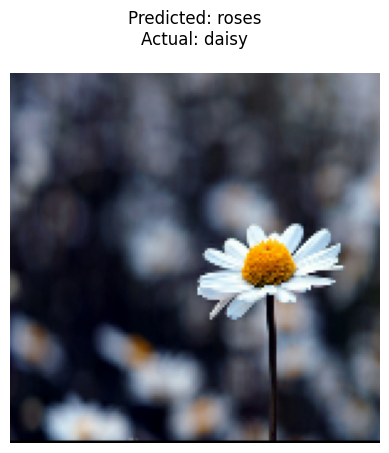

In [23]:
import random
import numpy as np
import matplotlib.pyplot as plt

class_names = ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']

# Select random image
i = random.randrange(len(test_images))

# Predict using preprocessed image
prediction = model.predict(test_ds[i:i+1], verbose=0)[0]

predicted = np.argmax(prediction)
actual = np.argmax(test_labels[i])

# Display original RGB image
plt.imshow(test_images[i].numpy().astype('uint8'))

plt.title(
    f"Predicted: {class_names[predicted]}\n"
    f"Actual: {class_names[actual]}\n"
    # f"Confidence: {prediction[predicted]*100:.2f}%"
)

plt.axis('off')
plt.show()